# 05 · Semantic search — does it actually beat keyword search?

Everyone assumes dense embedding retrieval beats keyword search. On general
prose it usually does. On **specialised jargon it frequently does not**, and
the reason is specific: embedding models are trained mostly on general web
text, where *covenant*, *impairment* and *securitisation* are rare or carry a
different everyday meaning. Exact-token matching can be worth more than
approximate semantics when the vocabulary is technical and the user knows it.

Which happens on 10-K risk factors is an empirical question. This notebook
answers it with a number.

### The three methods

| Method | How it ranks | Can it match without shared words? |
|---|---|---|
| **BM25** | Word overlap, weighting rare terms, discounting long passages | No |
| **Dense** | Cosine similarity between neural embeddings | **Yes** |
| **Hybrid** | Reciprocal Rank Fusion of both rankings | Yes |

BM25 is not a strawman. It is a genuinely hard baseline, and decades of
information-retrieval work have failed to beat it as often as people expect.

### Where the evaluation set comes from — no labelling, no LLM

A risk-factor section is written as short heading followed by longer
explanation:

> **We depend on a limited number of suppliers.**
> Our manufacturing operations rely on a small number of vendors for critical
> components. If any of these vendors were to fail…

**The heading is a query and we know which passage it introduced.** That gives
thousands of query/answer pairs for free.

**The bias this creates, and the control.** The heading's words also appear in
the body it introduces — so left alone, BM25 wins by finding the literal
heading text inside the passage, and the benchmark measures string overlap
rather than retrieval. So chunks store the **body only**; the heading is held
out and never indexed. A system must match the query to the *explanation*, on
meaning, not to a repeated string.

In [1]:
import warnings, importlib, time, pickle
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

import config, viz, retrieval
importlib.reload(retrieval)
from retrieval import (BM25, DenseIndex, reciprocal_rank_fusion, evaluate,
                       results_table, tokenize, build_relevance_sets)
viz.use_style()
print(config.describe())

repo   : X:\Projects\edgar-credit-signal
data   : X:\Projects\edgar-credit-signal\data
filings: X:\Projects\edgar-credit-signal\data\raw\filings


## Build the index

If you have not run it yet:

```
python build_index.py              # all sections
python build_index.py --sample 500 # quick trial first
```

The embedding model downloads once (~90 MB). On a CPU expect roughly 200
passages/second; on a GPU — Kaggle gives you one free — about ten times
that.

In [2]:
import json
chunks = pd.read_parquet(config.PROCESSED / "chunks.parquet")
queries_all = pd.read_parquet(config.PROCESSED / "heading_queries.parquet")
emb = np.load(config.PROCESSED / "chunk_embeddings.npy")
meta = json.loads((config.PROCESSED / "index_meta.json").read_text())

print(f"passages        {len(chunks):>10,}")
print(f"queries         {len(queries_all):>10,}")
print(f"embedding dim   {emb.shape[1]:>10,}")
print(f"built on        {meta['device']:>10}   "
      f"({meta['embed_per_sec']:,.0f} passages/sec)")
print()
print(chunks.n_chars.describe(percentiles=[.1,.5,.9]).round(0).to_string())

passages            47,391
queries             19,431
embedding dim          384
built on               cpu   (23 passages/sec)

count    47391.0
mean       629.0
std        180.0
min        200.0
10%        332.0
50%        685.0
90%        824.0
max        850.0


## Control — headings are never inside the passages

The evaluation queries **are** heading text, and the passages store the
explanation only. If a heading leaked into a body, BM25 could win by matching
a literal string and the lexical-vs-semantic comparison would measure nothing
at all.

This is not hypothetical. A chunker bug did exactly this: a heading whose
explanation fell just under the length floor was not recognised as a heading,
so it was merged into the passage behind it. On synthetic data it dragged
BM25's Recall@10 to 0.09 — it was ranking passages that merely contained the
heading *template*, from unrelated topics.

So the control is checked, not assumed.

In [3]:
heads = sorted({h for h in chunks["heading"] if h}, key=len, reverse=True)[:200]
probe = chunks["text"].sample(min(20_000, len(chunks)),
                              random_state=config.RANDOM_SEED)
leaked = sum(int(probe.str.contains(h, regex=False).any()) for h in heads)

print(f"headings checked        {len(heads):>8,}")
print(f"passages probed         {len(probe):>8,}")
print(f"headings found in body  {leaked:>8,}   <- must be 0")
assert leaked == 0, "heading leaked into an indexed passage — benchmark invalid"
print("\ncontrol passed: queries cannot be answered by string match")

headings checked             200
passages probed           20,000
headings found in body         0   <- must be 0

control passed: queries cannot be answered by string match


## The problem with one gold answer per query

Risk-factor boilerplate is reused **across companies**, not just forward in
time by one company. Law firms recycle language, and hundreds of firms write
"we depend on a limited number of suppliers" almost identically.

Mark exactly one of those passages correct and a system that returns a
perfectly relevant one is scored **wrong** every other time. Recall then
measures how duplicated the corpus is, not how good retrieval is.

Measured on a synthetic corpus built to have this property while developing
the benchmark: 1,200 passages carrying 16 distinct risk topics, a median of
86 near-identical passages per query. Under single-gold scoring BM25 recorded
**Recall@1 = 0.005** and read as a total failure. Scored against relevance
sets, *the same rankings* gave **0.930** — it was returning a correct passage
almost every time and being marked wrong for returning the wrong **copy** of
it.

The fix is standard information-retrieval practice: a query has a relevance
**set**, not a single answer. Here that set is the gold passage plus every
passage that is a near-duplicate of it, by TF-IDF cosine similarity above
0.85. Retrieving any member counts as a hit, which is what a user would
actually want.

Both scorings are reported below, because the gap between them *is* a
finding about the corpus.

### Not every heading is a query

Two kinds of text pass the heading test and are not retrieval tasks.

**Section dividers** — *"Risks Related to Our Organization and Structure:"*.
That names a GROUP of risks, so no single passage answers it and whatever a
system returns is scored arbitrarily.

**Bullet fragments** — *"•the price, availability and consumer demand for
alternative fuels;"*. A clause lifted out of a list, with no independent
meaning.

Both were found by printing ten random queries from the real corpus — a
control that should have existed from the start, and the reason this cell
prints its own sample below. Read them.

In [4]:
# Sampling keeps the relevance-set computation affordable; raise if you
# have time. Seeded, so the benchmark is reproducible.
N_QUERIES = 2000

import chunking
importlib.reload(chunking)

pos = {cid: i for i, cid in enumerate(chunks["chunk_id"])}
q = queries_all[queries_all["relevant_chunk_id"].isin(pos)].copy()

before = len(q)
q = q[q["query"].map(chunking.is_usable_query)]
print(f"query filter: dropped {before - len(q):,} dividers and bullet "
      f"fragments ({100*(before-len(q))/max(before,1):.1f}%), "
      f"{len(q):,} usable")
q = q.sample(min(N_QUERIES, len(q)), random_state=config.RANDOM_SEED)
q["gold_idx"] = q["relevant_chunk_id"].map(pos)

texts = chunks["text"].tolist()
gold_idx = q["gold_idx"].tolist()
print(f"benchmark queries: {len(q):,}\n")

print("sample — every line should read like something an analyst would type")
for text in q["query"].head(10):
    print(f"  - {text[:96]}")

query filter: dropped 2,931 dividers and bullet fragments (15.1%), 16,500 usable
benchmark queries: 2,000

sample — every line should read like something an analyst would type
  - We maintain cash balances in our bank accounts that exceed the FDIC insurance limitation.
  - We review the recoverability of goodwill annually, as of the first day of our fourth quarter, an
  - Our ability to realize our deferred tax asset may be reduced, which may adversely impact our res
  - We are dependent upon key personnel.
  - A cyber incident or data breach could result in information theft, data corruption, operational 
  - Under the Tax Cuts and Jobs
  - Our success depends upon broad market acceptance of our technology that has not yet been achieve
  - Geographic and industry market concentration makes our results of operations vulnerable to regio
  - If we fail to maintain effective internal controls over financial reporting, we may not be able 
  - (ii) Risks Related to Our Indebtedness


In [5]:
t0 = time.time()
relsets = build_relevance_sets(gold_idx, texts, threshold=0.85)
sizes = np.array([len(s) for s in relsets])

print(f"relevance sets built in {time.time()-t0:.0f}s")
print(f"  set size   median {int(np.median(sizes))}  mean {sizes.mean():.1f}  "
      f"max {sizes.max()}")
print(f"  {(sizes==1).mean():.1%} of queries have a genuinely unique answer")
print(f"  {(sizes>10).mean():.1%} have more than 10 near-identical passages")
print()
print("A large median here means the corpus is heavily boilerplated —")
print("which is itself a finding about how 10-K risk factors are written.")

relevance sets built in 9s
  set size   median 1  mean 1.1  max 7
  89.6% of queries have a genuinely unique answer
  0.0% have more than 10 near-identical passages

A large median here means the corpus is heavily boilerplated —
which is itself a finding about how 10-K risk factors are written.


## BM25 — the lexical baseline

In [6]:
with open(config.PROCESSED / "bm25.pkl", "rb") as f:
    bm25 = pickle.load(f)
print(f"BM25 vocabulary: {len(bm25.idf):,} terms")

lat, bm_rank = [], []
for text in q["query"]:
    s = time.time(); bm_rank.append(bm25.top_k(text, 10))
    lat.append((time.time()-s)*1000)
bm25_ms = float(np.median(lat))
print(f"median query latency: {bm25_ms:.1f} ms")

BM25 vocabulary: 25,081 terms
median query latency: 3.0 ms


## Dense — embedding retrieval

Queries are encoded with the **same model** that encoded the passages. Using
a different one would put them in unrelated vector spaces and the comparison
would be meaningless.

In [7]:
from sentence_transformers import SentenceTransformer
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(meta["model"], device=device)
qvecs = model.encode(q["query"].tolist(), batch_size=256,
                     convert_to_numpy=True, normalize_embeddings=True,
                     show_progress_bar=True)

dense = DenseIndex(emb)
lat, dn_rank = [], []
for i in range(len(q)):
    s = time.time(); dn_rank.append(dense.top_k(qvecs[i], 10))
    lat.append((time.time()-s)*1000)
dense_ms = float(np.median(lat))
print(f"median query latency: {dense_ms:.2f} ms  (device: {device})")

Batches: 100%|██████████| 8/8 [00:13<00:00,  1.75s/it]


median query latency: 5.00 ms  (device: cpu)


## Hybrid — Reciprocal Rank Fusion

The two systems' scores are **not comparable**: BM25 scores are unbounded
sums, cosine similarities live in [-1, 1]. Normalising them to a common range
is a fudge that silently depends on the score distribution of whichever
corpus you happen to have.

RRF avoids the problem by fusing on **rank** alone — each list contributes
1/(60 + rank) per document. Only the order matters, which is the only thing
the two methods agree on the meaning of.

In [8]:
lat, hy_rank = [], []
for i, text in enumerate(q["query"]):
    s = time.time()
    hy_rank.append(reciprocal_rank_fusion(
        [bm25.top_k(text, 20), dense.top_k(qvecs[i], 20)], top_n=10))
    lat.append((time.time()-s)*1000)
hybrid_ms = float(np.median(lat))
print(f"median query latency: {hybrid_ms:.1f} ms")

median query latency: 8.2 ms


## Results

In [9]:
strict = results_table([
    evaluate(bm_rank, gold_idx, "BM25 (lexical)",   bm25_ms),
    evaluate(dn_rank, gold_idx, "Dense (embeddings)", dense_ms),
    evaluate(hy_rank, gold_idx, "Hybrid (RRF)",     hybrid_ms)])
print("STRICT — one gold answer per query (understates when duplicates exist)")
display(strict)

rel = results_table([
    evaluate(bm_rank, relsets, "BM25 (lexical)",     bm25_ms),
    evaluate(dn_rank, relsets, "Dense (embeddings)", dense_ms),
    evaluate(hy_rank, relsets, "Hybrid (RRF)",       hybrid_ms)])
print("\nRELEVANCE SETS — near-duplicates count as correct (the headline)")
display(rel)

rel.to_csv(config.PROCESSED / "retrieval_benchmark.csv", index=False)

STRICT — one gold answer per query (understates when duplicates exist)


,method,Recall@1,Recall@5,Recall@10,MRR,median ms,queries
0,BM25 (lexical),0.151,0.2785,0.330,0.2060,3.02,2000
1,Dense (embeddings),0.089,0.1920,0.238,0.1323,5.00,2000
2,Hybrid (RRF),0.129,0.2690,0.337,0.1880,8.20,2000



RELEVANCE SETS — near-duplicates count as correct (the headline)


,method,Recall@1,Recall@5,Recall@10,MRR,median ms,queries
0,BM25 (lexical),0.159,0.2835,0.3365,0.2124,3.02,2000
1,Dense (embeddings),0.097,0.1945,0.2435,0.1383,5.00,2000
2,Hybrid (RRF),0.138,0.2750,0.3420,0.1950,8.20,2000


findfont: Failed to find font weight 600, now using 700.
findfont: Failed to find font weight 600, now using 700.


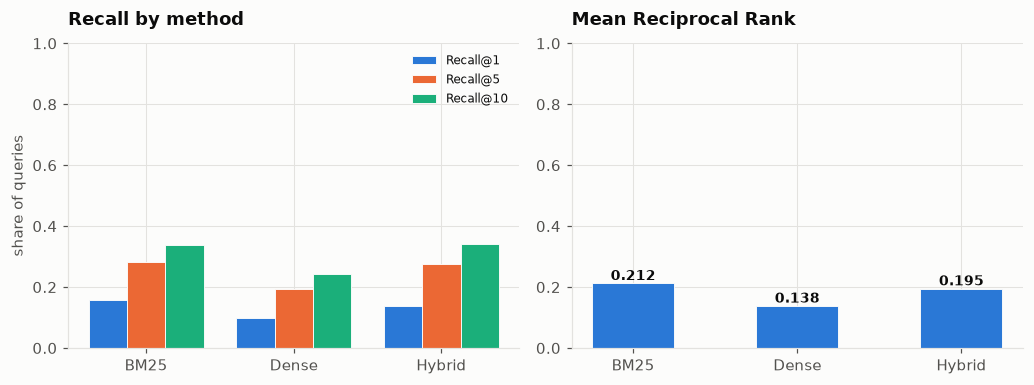

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))

methods = rel["method"].tolist()
x = np.arange(len(methods)); w = 0.26
for i, (col, lab) in enumerate([("Recall@1","Recall@1"),
                                 ("Recall@5","Recall@5"),
                                 ("Recall@10","Recall@10")]):
    axes[0].bar(x + (i-1)*w, rel[col], w, color=viz.SERIES[i], label=lab,
                edgecolor=viz.SURFACE, linewidth=0.6)
axes[0].set_xticks(x); axes[0].set_xticklabels([m.split(" ")[0] for m in methods])
axes[0].set_title("Recall by method"); axes[0].set_ylabel("share of queries")
axes[0].set_ylim(0, 1); axes[0].legend(fontsize=8)

axes[1].bar(x, rel["MRR"], 0.5, color=viz.SERIES[0],
            edgecolor=viz.SURFACE, linewidth=0.6)
for xi, v in zip(x, rel["MRR"]):
    axes[1].annotate(f"{v:.3f}", (xi, v), ha="center", va="bottom",
                     fontsize=9, fontweight="600", color=viz.INK)
axes[1].set_xticks(x); axes[1].set_xticklabels([m.split(" ")[0] for m in methods])
axes[1].set_title("Mean Reciprocal Rank"); axes[1].set_ylim(0, 1)

plt.tight_layout(); plt.show()

## Read the disagreements by hand

The most informative cell in this notebook. Find queries where the two
methods disagree most and look at what each returned. That is where you learn
*why* one wins — and whether the winner is winning for a good reason.

In [11]:
def rank_of(ranked, gold_set):
    for pos_, d in enumerate(ranked, 1):
        if d in gold_set: return pos_
    return 999

bm_pos = np.array([rank_of(r, g) for r, g in zip(bm_rank, relsets)])
dn_pos = np.array([rank_of(r, g) for r, g in zip(dn_rank, relsets)])
gap = bm_pos - dn_pos                      # positive => dense did better

for label, order in [("DENSE WINS BY MOST", np.argsort(-gap)),
                     ("BM25 WINS BY MOST",  np.argsort(gap))]:
    print(f"\n{'='*66}\n{label}\n{'='*66}")
    for j in order[:2]:
        print(f"\nquery : {q['query'].iloc[j][:100]}")
        print(f"        BM25 rank {bm_pos[j] if bm_pos[j]<999 else 'miss':>4} | "
              f"Dense rank {dn_pos[j] if dn_pos[j]<999 else 'miss':>4}")
        print(f"  gold : {texts[gold_idx[j]][:190]}...")
        print(f"  BM25 top-1 : {texts[bm_rank[j][0]][:150]}...")
        print(f"  Dense top-1: {texts[dn_rank[j][0]][:150]}...")


DENSE WINS BY MOST

query : Demand for our infrastructure products and coating services is highly dependent upon the overall lev
        BM25 rank miss | Dense rank    1
  gold : We manufacture and distribute engineered infrastructure products for lighting and traffic, utility and other specialty applications. Our Coatings segments serve many construction‑related ind...
  BM25 top-1 : In addition, sales in our Engineered Support Structures segment, particularly our lighting, traffic and highway safety products, are highly dependent ...
  Dense top-1: We manufacture and distribute engineered infrastructure products for lighting and traffic, utility and other specialty applications. Our Coatings segm...

query : Our BOT model and the accounting for our projects as sales-type leases could result in a difference 
        BM25 rank miss | Dense rank    1
  gold : While we recognize a large portion of the revenue from each project when it goes on-line, all of the cash flow from the project 

## BM25 won. Now find out whether it deserved to.

Before reporting "lexical beats semantic on financial text", there is a
confound in the evaluation that has to be ruled out — and it is a confound
that *favours the winner*.

**The queries are headings written by the same person who wrote the passage.**
A filer writes "We are or may be subject to potential liability in connection
with pending or threatened legal proceedings" and then opens the explanation
with almost exactly those words. That is not how an analyst searches. An
analyst types *"litigation exposure"* and expects the paragraph back.

So the benchmark hands BM25 a structural advantage: high vocabulary overlap
between query and answer, by construction. The measured gap is therefore an
**upper bound** on BM25's real-world advantage, not an estimate of it.

That is a testable claim rather than a caveat to wave at. Split the queries by
how much of their vocabulary actually appears in the gold passage. If BM25's
lead lives entirely in the high-overlap third and collapses in the low-overlap
third, the mechanism is confirmed — BM25 is winning where the author repeated
themselves, not where meaning has to be matched.

In [12]:
STOP = set("""a an the and or of to in for on with our we us it its is are was
were be been being that this these those as at by from may will can could
would should our their his her not no any all such other than then there
here which who whom whose what when where how if but into over under about
also more most some many much very each every both few own same so only""".split())

def coverage(query: str, passage: str) -> float:
    """Share of the query's content words that literally appear in the gold
    passage. This is the quantity BM25 can exploit and dense cannot."""
    qt = {t for t in tokenize(query) if t not in STOP and len(t) > 2}
    pt = set(tokenize(passage))
    return len(qt & pt) / max(len(qt), 1)

cov = np.array([coverage(text, texts[g]) for text, g in zip(q["query"], gold_idx)])
edges = np.quantile(cov, [1/3, 2/3])
stratum = np.digitize(cov, edges)
NAMES = ["low — paraphrase-like", "medium", "high — heading echoed"]

rows = []
for s in range(3):
    idx = np.flatnonzero(stratum == s)
    if len(idx) == 0:          # coverage can tie heavily; skip empty strata
        print(f"stratum '{NAMES[s]}' is empty — coverage values are heavily tied")
        continue
    for name, ranks in [("BM25", bm_rank), ("Dense", dn_rank), ("Hybrid", hy_rank)]:
        r = evaluate([ranks[i] for i in idx], [relsets[i] for i in idx], name)
        rows.append({"overlap": NAMES[s], "method": name, "n": len(idx),
                     "mean coverage": round(float(cov[idx].mean()), 3),
                     "Recall@10": round(r.recall_at_10, 4),
                     "MRR": round(r.mrr, 4)})
strat = pd.DataFrame(rows)

print("query-term coverage overall: "
      f"median {np.median(cov):.2f}  mean {cov.mean():.2f}")
print("(1.00 would mean every content word of the query appears in the answer)\n")
display(strat.pivot(index="overlap", columns="method", values="MRR")
             .reindex(NAMES).round(4))
display(strat.pivot(index="overlap", columns="method", values="Recall@10")
             .reindex(NAMES).round(4))
strat.to_csv(config.PROCESSED / "retrieval_by_overlap.csv", index=False)

query-term coverage overall: median 0.40  mean 0.42
(1.00 would mean every content word of the query appears in the answer)



method,BM25,Dense,Hybrid
overlap,,,
low — paraphrase-like,0.0117,0.0243,0.0153
medium,0.0971,0.0935,0.1084
high — heading echoed,0.4503,0.2591,0.3965


method,BM25,Dense,Hybrid
overlap,,,
low — paraphrase-like,0.0300,0.0679,0.0506
medium,0.2157,0.1943,0.2353
high — heading echoed,0.6613,0.4156,0.6452


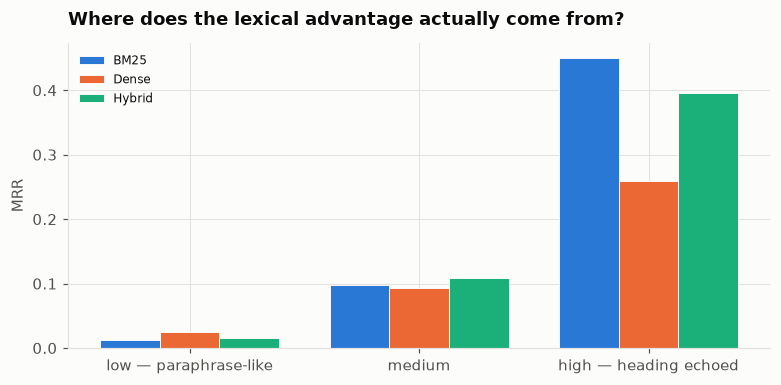

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
piv = strat.pivot(index="overlap", columns="method", values="MRR").reindex(NAMES)
x = np.arange(len(NAMES)); w = 0.26
for i, m in enumerate(["BM25", "Dense", "Hybrid"]):
    ax.bar(x + (i-1)*w, piv[m], w, color=viz.SERIES[i], label=m,
           edgecolor=viz.SURFACE, linewidth=0.6)
ax.set_xticks(x); ax.set_xticklabels(NAMES)
ax.set_ylabel("MRR"); ax.legend(fontsize=8, frameon=False)
ax.set_title("Where does the lexical advantage actually come from?")
plt.tight_layout(); plt.show()

### Reading that chart

**BM25's lead concentrated in the right-hand bars** — confirmed. Lexical
matching wins where the filer repeated their own heading, which is an artefact
of how the evaluation set was built rather than a property of financial
language. Report the headline number *with* this stratification, because
without it the claim overstates.

**BM25 ahead everywhere, including the left bars** — stronger result. Even
where the query shares little vocabulary with the answer, exact tokens beat
a general-purpose embedding. That is a real finding about domain vocabulary
and worth stating plainly.

**Dense ahead on the left, behind on the right** — the textbook pattern, and
the case for hybrid: the two methods are good at different queries, which is
exactly the condition under which fusion helps.

## Robustness — does the relevance-set threshold change the answer?

0.85 was a judgement call. A conclusion that flips at 0.75 is not a
conclusion, so the threshold is swept rather than defended.

Note what the strict-versus-relevance-set tables already showed: on the real
corpus the two barely differ, so near-duplicates at this threshold are rare.
That is worth knowing on its own — cross-firm risk-factor boilerplate is
**reworded** rather than copied verbatim, which is why TF-IDF cosine rarely
reaches 0.85. The synthetic corpus used while building this was more
duplicated than reality.

In [14]:
sweep = []
for th in (0.95, 0.85, 0.75, 0.65):
    rs = build_relevance_sets(gold_idx, texts, threshold=th)
    sz = np.array([len(x) for x in rs])
    for name, ranks in [("BM25", bm_rank), ("Dense", dn_rank), ("Hybrid", hy_rank)]:
        r = evaluate(ranks, rs, name)
        sweep.append({"threshold": th, "median set size": int(np.median(sz)),
                      "mean set size": round(float(sz.mean()), 1),
                      "method": name, "Recall@10": round(r.recall_at_10, 4),
                      "MRR": round(r.mrr, 4)})
sw = pd.DataFrame(sweep)
display(sw.pivot(index=["threshold", "median set size", "mean set size"],
                 columns="method", values="MRR").round(4))

winner = (sw.loc[sw.groupby("threshold")["MRR"].idxmax()]
            .set_index("threshold")["method"])
print("\nbest method at each threshold:")
print(winner.to_string())
print("\nstable answer" if winner.nunique() == 1 else
      "\nANSWER FLIPS — the threshold is doing the work, not the retrieval")
sw.to_csv(config.PROCESSED / "retrieval_threshold_sweep.csv", index=False)

,,method,BM25,Dense,Hybrid
threshold,median set size,mean set size,,,
0.65,1,1.4,0.2224,0.1485,0.2052
0.75,1,1.2,0.2161,0.1414,0.1976
0.85,1,1.1,0.2124,0.1383,0.1950
0.95,1,1.1,0.2085,0.1356,0.1916



best method at each threshold:
threshold
0.65    BM25
0.75    BM25
0.85    BM25
0.95    BM25

stable answer


## Verdict

Three things to take from this notebook, in order of how much they are worth
saying out loud.

**1 · The measured answer.** Read it off the relevance-set table and the
stratification together, not from the headline row alone.

**2 · The evaluation's own bias, named and quantified.** Heading-derived
queries share vocabulary with their answers by construction. That is why the
overlap stratification exists — it converts a hand-wave into a number.

**3 · The practical reading.** If BM25 wins, the cheaper, faster, fully
interpretable system is also the better one, and the next experiment is a
finance-domain embedding model rather than a bigger general-purpose one.
Hybrid buying a little Recall@10 while costing MRR and roughly 3x the latency
is a real engineering trade-off, not a free win.

And note the latency column. Dense search over an exact FAISS index is fast;
BM25 over a 25,000-term vocabulary is slower than people expect; fusion pays
both costs.

In [15]:
best = rel.loc[rel["MRR"].idxmax()]
print(f"Best by MRR: {best['method']}")
print(f"  Recall@1  {best['Recall@1']:.4f}")
print(f"  Recall@5  {best['Recall@5']:.4f}")
print(f"  Recall@10 {best['Recall@10']:.4f}")
print(f"  MRR       {best['MRR']:.4f}")
print(f"  latency   {best['median ms']:.2f} ms median")
print(f"\nover {int(best['queries']):,} queries, "
      f"{len(chunks):,} passages, {chunks.cik.nunique():,} firms")
print(f"\nmedian query-term coverage {np.median(cov):.2f} — "
      f"the number that decides how much to trust the headline")

Best by MRR: BM25 (lexical)
  Recall@1  0.1590
  Recall@5  0.2835
  Recall@10 0.3365
  MRR       0.2124
  latency   3.02 ms median

over 2,000 queries, 47,391 passages, 433 firms

median query-term coverage 0.40 — the number that decides how much to trust the headline
